# 01. Data audit and target analysis

**The question this notebook answers:** what is wrong with this data, and can we trust the answer column (`defaulted`)?

**How to read it.** Every section has three parts: a short explanation in plain words, a cell that runs the real code on the real data, and what the output means. Nothing here is a copy of the logic; the repairs come from `credit_risk.cleaning.Cleaner`, the same code that builds the data contract.

**What the brief asks (Part A, first two bullets):**
- *Data audit and cleaning:* profile all three files and find duplicates, inconsistent categories and free text, unit errors, mixed formats, impossible values, and contradictions between files. For each issue decide to **fix, flag or drop**, give the reason, and report how many rows it affects.
- *Target analysis:* default rate overall, by issue month and by term, and class balance. Explain how removing loans still in progress could bias the default rate of recent loans, especially 60-month ones.

The only rows we ever drop are duplicates. Everything else is repaired in place, set to missing with a flag, or kept and flagged.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")                      # run everything from the repository root

import numpy as np
import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.proportion import proportion_confint

from credit_risk.io import load_applications, parse_dates
from credit_risk.cleaning import Cleaner

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

app = pd.read_csv("data/applications.csv", low_memory=False)     # the loan and the applicant, plus `defaulted`
bur = pd.read_csv("data/credit_bureau.csv", low_memory=False)    # the credit report pulled at application
srv = pd.read_csv("data/loan_servicing.csv", low_memory=False)   # what happened after the loan (audit only)
print(f"applications {app.shape}   bureau {bur.shape}   servicing {srv.shape}")

applications (30600, 20)   bureau (30000, 22)   servicing (30000, 11)


## 0. Three files, three moments in a loan's life

| File | When the information exists | Used for |
|---|---|---|
| `applications.csv` | the day the loan is approved | model inputs, plus the answer column `defaulted` |
| `credit_bureau.csv` | the day the loan is approved | model inputs |
| `loan_servicing.csv` | **years later** (a March 2019 snapshot) | checking the answer column only, never a model input |

`applications` has 30,600 rows but the other two have 30,000, so something is repeated. That is our first finding.

## 1. Duplicates

*A loan should appear once. If an id appears twice, which copy do we believe?*

In [2]:
dup_ids = app.id[app.id.duplicated()].unique()
pairs = app[app.id.isin(dup_ids)].sort_values("id")
first = pairs.groupby("id").head(1).set_index("id").sort_index()
second = pairs.groupby("id").tail(1).set_index("id").sort_index()
differs = ~((first == second) | (first.isna() & second.isna()))
print(f"{len(dup_ids)} ids appear twice -> {len(app)} rows hold {app.id.nunique():,} loans")
print("\ncolumns where the two copies disagree (number of ids):")
print(differs.sum()[lambda s: s > 0].to_string())
print("\nexample (same loan, two rows):")
example = dup_ids[0]
print(app[app.id == example][["id", "issue_d", "loan_amnt", "dti", "emp_title", "defaulted"]].to_string(index=False))

600 ids appear twice -> 30600 rows hold 30,000 loans

columns where the two copies disagree (number of ids):
emp_title    528
dti          600

example (same loan, two rows):
        id  issue_d  loan_amnt   dti emp_title  defaulted
8acbab3c06 Jan-2013    14400.0 15.53 Hillstone          0
8acbab3c06 Jan-2013    14400.0 15.54 HILLSTONE          0


**Reading it.** The two copies agree on everything that matters (amount, date, the label). They differ only in the capital letters of the job title and in `dti` at the second decimal. So nothing is lost by keeping the first copy.

**Decision: drop the 600 extra rows** (the only rows we drop). After this, every loan has exactly one application row and one bureau row.

## 2. Inconsistent categories and free text

*The same thing written in different ways splits one group into many.*

In [3]:
a = app.drop_duplicates("id").copy()                      # one row per loan from here on
raw_state = a.addr_state.astype(str)
odd = raw_state[(raw_state != raw_state.str.strip().str.upper()) | (raw_state.str.len() > 2)]
from credit_risk.cleaning import STATE_NAMES
tidy = raw_state.str.strip()
tidy = tidy.str.lower().map(STATE_NAMES).fillna(tidy.str.upper())
print(f"addr_state: {raw_state.nunique()} distinct spellings, which are really {tidy.nunique()} states; {len(odd):,} rows are not a clean two-letter code")
print(odd.value_counts().head(8).to_string())

title = a.emp_title.dropna().astype(str)
print(f"\nemp_title: {title.nunique():,} distinct texts; {title.str.strip().str.lower().nunique():,} after lower-casing and trimming")
variants = title.groupby(title.str.strip().str.lower()).agg(lambda s: sorted(s.unique()))
print("the same job typed several ways, e.g.:")
for key, v in variants[variants.map(len) > 2].head(3).items():
    print("  ", v)

addr_state: 154 distinct spellings, which are really 49 states; 3,000 rows are not a clean two-letter code
addr_state
California    148
ca            142
 CA           136
 FL            95
Texas          93
tx             80
New York       77
 NY            75

emp_title: 15,657 distinct texts; 13,484 after lower-casing and trimming


the same job typed several ways, e.g.:
   ['ACCOUNT DIRECTOR', 'Account Director', 'Account Director ']
   ['ACCOUNT EXECUTIVE', 'Account Executive', 'Account Executive ', 'Account executive', 'account executive']
   ['ACCOUNT MANAGER', 'ACCOUNT MANAGER ', 'Account Manager', 'Account Manager ', 'Account manager', 'Account manager ', 'account manager']


**Reading it.** `ca`, ` TX` and `California` are all the same state. Left alone, a model or a WoE table would treat them as different places. The job title is free text typed by the applicant, so it needs the same trimming and later a grouping (notebook 04).

**Decision: fix.** Strip spaces, upper-case, map full names to codes; lower-case and trim job titles.

## 3. Mixed formats

*A date written three ways cannot be sorted, and our time split depends on dates.*

In [4]:
def date_format(s):
    s = s.astype(str)
    return pd.Series(np.select(
        [s.str.match(r"^[A-Za-z]{3}-\d{4}$"), s.str.match(r"^\d{4}-\d{2}-\d{2}$"), s.str.match(r"^\d{2}/\d{4}$")],
        ["Mon-YYYY (Jul-2015)", "YYYY-MM-DD (2015-07-01)", "MM/YYYY (07/2015)"], "other"), index=s.index)

print("issue_d formats:\n", date_format(a.issue_d).value_counts().to_string())
print("\nearliest_cr_line formats:\n", date_format(bur.earliest_cr_line).value_counts().to_string())
print("\nterm as stored:", a.term.unique().tolist())

issue_d formats:
 Mon-YYYY (Jul-2015)        28800
YYYY-MM-DD (2015-07-01)      615
MM/YYYY (07/2015)            585



earliest_cr_line formats:
 Mon-YYYY (Jul-2015)        28800
YYYY-MM-DD (2015-07-01)      607
MM/YYYY (07/2015)            593

term as stored: [' 36 months', ' 60 months']


**Reading it.** About 4% of dates use a different spelling, and `term` has a leading space (`' 36 months'`). A string comparison would put 07/2015 before Jan-2013.

**Decision: fix.** Parse all three date formats to a real date; turn `term` into the number 36 or 60. The split at 31 Dec 2014 is only trustworthy after this.

## 4. Unit errors (the hardest ones)

*A number is believable on its own but wrong because of its units. A range check cannot see these; a cross-check against another field can.*

We use the pipeline's own `Cleaner` to find them, then look at the evidence behind each one.

In [5]:
joined = load_applications()                              # applications + bureau, one row per loan
clean = Cleaner().fit(joined).transform(joined)
print("rows repaired by the Cleaner:")
print(pd.Series({
    "income typed in thousands": int(clean.annual_inc_fixed.sum()),
    "loan amount 10x too large": int(clean.loan_amnt_fixed.sum()),
    "revolving balance 10x too large": int(clean.revol_bal_fixed.sum()),
}).to_string())

rows repaired by the Cleaner:
income typed in thousands          899
loan amount 10x too large          300
revolving balance 10x too large    308


### 4a. Income typed in thousands
An income of `53` next to thousands of `53000` is almost certainly fifty-three thousand. Evidence: after multiplying by 1,000 these loans look like everyone else.

In [6]:
small = a.annual_inc < 1000
print(f"{int(small.sum())} loans have annual_inc below $1,000 (smallest ${a.annual_inc.min():.2f})")
print(f"median income of those loans x 1000: ${a.annual_inc[small].median() * 1000:,.0f}   vs   everyone else: ${a.annual_inc[~small].median():,.0f}")
print(f"default rate: {a.defaulted[small].mean():.1%} vs {a.defaulted[~small].mean():.1%} (overall {a.defaulted.mean():.1%})")
print("incomes between $1,000 and $5,000:", int(a.annual_inc.between(1000, 5000).sum()), "(a real gap, so the rule is not ambiguous)")

899 loans have annual_inc below $1,000 (smallest $11.50)
median income of those loans x 1000: $63,500   vs   everyone else: $65,000
default rate: 18.2% vs 18.7% (overall 18.7%)
incomes between $1,000 and $5,000: 0 (a real gap, so the rule is not ambiguous)


### 4b. Loan amount 10 times too large
The monthly **installment** is correct, so the payment the formula gives for `loan_amnt` is ten times the installment. Many of these exceed the $40,000 product limit, but some do not, and a range check would miss them.

In [7]:
t = a.term.astype(str).str.extract(r"(\d+)")[0].astype(int)
r = a.int_rate / 1200
schedule = a.loan_amnt * r / (1 - (1 + r) ** -t)
ratio = schedule / a.installment
x10 = a[(ratio - 10).abs() < 0.5]
print(f"{len(x10)} loans where the scheduled payment on loan_amnt is 10x the installment")
print(f"  of which loan_amnt above the $40,000 limit: {int((x10.loan_amnt > 40000).sum())}; inside the limit: {int((x10.loan_amnt <= 40000).sum())}")
inside = x10[x10.loan_amnt <= 40000]
normal = a[(ratio - 1).abs() < 0.02]
print(f"\nthe {len(inside)} 'inside the limit' amounts: smallest ${inside.loan_amnt.min():,.0f}; any below $10,000? {int((inside.loan_amnt < 10000).sum())}")
print(f"if the installment were the wrong one, about {len(inside) * (normal.loan_amnt < 10000).mean():.0f} would be below $10,000 (as in {(normal.loan_amnt < 10000).mean():.0%} of normal loans)")
print(f"share of normal loans at or below $4,000 (whose 10x lands inside the limit): {(normal.loan_amnt <= 4000).mean():.1%}  ->  expected among 300 errors: {300 * (normal.loan_amnt <= 4000).mean():.0f}")

300 loans where the scheduled payment on loan_amnt is 10x the installment
  of which loan_amnt above the $40,000 limit: 280; inside the limit: 20

the 20 'inside the limit' amounts: smallest $14,500; any below $10,000? 0
if the installment were the wrong one, about 6 would be below $10,000 (as in 32% of normal loans)
share of normal loans at or below $4,000 (whose 10x lands inside the limit): 6.6%  ->  expected among 300 errors: 20


**Reading it.** All 300 are the same error: the amount is ten times too big. The 20 that look fine are small loans (true amount of at least $1,450) whose inflated amount stayed under $40,000. Two facts prove it: none of the 20 is below $10,000 (they would be if the installment were wrong), and the count matches what we expect from small loans (about 20). **Decision: fix, divide by 10.** After this the recomputed payment matches the installment.

### 4c. Revolving balance 10 times too large
There is no amount-versus-installment shortcut here, but two other relationships give it away: balance / credit limit should equal the reported utilisation, and a revolving balance cannot exceed the total current balance (which contains it).

In [8]:
fx = clean[clean.revol_bal_fixed]
cols = ["id", "revol_bal", "total_rev_hi_lim", "revol_util"]
shown = joined.loc[fx.index[:4], cols].assign(revol_bal_after_fix=fx.revol_bal[:4].values)
shown["implied_util_before"] = (100 * shown.revol_bal / shown.total_rev_hi_lim).round(0)
shown["implied_util_after"] = (100 * shown.revol_bal_after_fix / shown.total_rev_hi_lim).round(0)
print(f"{len(fx)} loans repaired. Four examples (utilisation is in %):")
print(shown.to_string(index=False))

308 loans repaired. Four examples (utilisation is in %):
        id  revol_bal  total_rev_hi_lim  revol_util  revol_bal_after_fix  implied_util_before  implied_util_after
dcbd3398e8   105110.0           32300.0        32.5              10511.0                325.0                33.0
8a023cab21    32360.0           12300.0        26.3               3236.0                263.0                26.0
6c0f3cf6bc   194450.0           42800.0        45.4              19445.0                454.0                45.0
013737040c     2060.0            3000.0         6.9                206.0                 69.0                 7.0


**Reading it.** Before the fix the balance implies a utilisation of several hundred percent (325%) while the bureau reports 32.5%; after dividing by 10 the two agree. **Decision: fix, divide by 10.** This one was missed in our first pass and found only by the cross-check, which is the lesson of this section: *unit errors hide inside plausible ranges and show up in relationships between fields.*

## 5. Impossible values

*Some values cannot be true: a negative utilisation, a score band written backwards, a credit history that starts after the loan.*

In [9]:
print("negative revol_util:", int((bur.revol_util < 0).sum()), "  negative bc_util:", int((bur.bc_util < 0).sum()))
negs = joined[joined.revol_util < 0]
implied = 100 * negs.revol_bal / negs.total_rev_hi_lim.where(negs.total_rev_hi_lim > 0)
print(f"for negative revol_util, |value| is within 2 points of balance/limit in {(abs(negs.revol_util.abs() - implied) <= 2).mean():.0%} of rows -> a sign flip")

print("\nFICO low above high:", int((bur.fico_range_low > bur.fico_range_high).sum()),
      "| band width in the other rows (points):", sorted(int(w) for w in (bur.fico_range_high - bur.fico_range_low)[bur.fico_range_low <= bur.fico_range_high].unique()))

issue, credit = parse_dates(a.issue_d), parse_dates(bur.earliest_cr_line)
gap = (parse_dates(joined.issue_d).dt.to_period("M").astype("int64") - parse_dates(joined.earliest_cr_line).dt.to_period("M").astype("int64"))
print("credit history starts after the loan:", int((gap < 0).sum()), "loans; months after issue ranges from", int((-gap[gap < 0]).min()), "to", int((-gap[gap < 0]).max()))
print("interest rate exactly 6.00 (a placeholder):", int((a.int_rate == 6.0).sum()))

negative revol_util: 295   negative bc_util: 290
for negative revol_util, |value| is within 2 points of balance/limit in 97% of rows -> a sign flip

FICO low above high: 150 | band width in the other rows (points): [4, 5]


credit history starts after the loan: 300 loans; months after issue ranges from 1 to 23
interest rate exactly 6.00 (a placeholder): 8


**Decisions**

| Problem | Decision | Reason |
|---|---|---|
| Negative `revol_util` | **fix** (take the absolute value) | the balance and limit prove it is a sign flip |
| Negative `bc_util` | **flag**, set to missing | no balance column to prove it (a later test shows the sign flip is almost surely right, but the effect on the model is negligible) |
| FICO low above high | **fix** (swap) | values are valid, only the order is wrong |
| Credit history after the loan | **flag**, set to missing | the error looks random, so the true date cannot be recovered; inventing one is not honest |
| Interest rate exactly 6.00 | **fix** (median of the sub-grade) | a placeholder, not a real rate |

## 6. Contradictions between files

*Do the three files tell the same story?* Here `loan_servicing` earns its place: it is the **audit tool** for the answer column.

In [10]:
m = a.merge(bur, on="id").merge(srv, on="id")
print("bureau_recovery_flag (bureau file) vs recoveries > 0 (servicing file):")
print(pd.crosstab(m.bureau_recovery_flag, m.recoveries > 0))
print("\nbureau_recovery_flag vs the label:")
print(pd.crosstab(m.bureau_recovery_flag, m.defaulted))
print("\nchecks of `defaulted` against the payment history (number of loans that FAIL each check):")
print(pd.read_csv("reports/a1_label_audit/tables/label_checks.csv").head(5).to_string(index=False))

bureau_recovery_flag (bureau file) vs recoveries > 0 (servicing file):
recoveries            False  True 
bureau_recovery_flag              
0                     25793      0
1                         0   4207

bureau_recovery_flag vs the label:
defaulted                 0     1
bureau_recovery_flag             
0                     24383  1410
1                         0  4207

checks of `defaulted` against the payment history (number of loans that FAIL each check):
                                           check  loans
defaulted loans whose principal was fully repaid      0
                  paid loans with recoveries > 0      0
        paid loans with debt_settlement_flag = Y      0
                 paid loans with total_pymnt = 0      0
   paid loans that repaid under 99% of principal      0


**Reading it.**
- `defaulted` agrees with the payments: **zero** loans labelled "repaid" show missing principal, recoveries or a settlement, and none labelled "defaulted" repaid in full. So the label can be trusted.
- `bureau_recovery_flag` sits in the *bureau* file, but it is a copy of "money was recovered after a default", which can only be known years later. Every loan with the flag is a default. A model given this column would look brilliant and be useless on a new applicant. This is **leakage**.

**Decision: drop `bureau_recovery_flag` and every servicing column from the model.**

## 7. All decisions in one table

| Issue | Rows | Decision |
|---|---|---|
| Duplicate loan ids | 600 | **drop** the extra copies |
| Messy states and job titles | ~3,000 states | **fix** |
| Date formats (issue date, credit line) | 1,200 each | **fix** |
| `term` text with a leading space | all 30,000 | **fix** |
| Income typed in thousands | 899 | **fix** (x1,000) |
| Loan amount 10x too large | 300 | **fix** (÷10) |
| Revolving balance 10x too large | 308 | **fix** (÷10) |
| Negative `revol_util` | 295 | **fix** (absolute value) |
| Negative `bc_util` | 290 | **flag**, set to missing |
| FICO band swapped | 150 | **fix** |
| Credit history after the loan | 300 | **flag**, set to missing |
| Placeholder interest rate | 8 | **fix** |
| `bureau_recovery_flag` | 4,207 flagged | **drop** (leak) |
| Servicing file | all | audit only |

The full list with reasons is `docs/issue_log.md`.

---
# Target analysis: what are we predicting?

*`defaulted = 1` means the loan was Charged Off or Default; `0` means Fully Paid. Loans still being repaid were removed before we got the file.*

In [11]:
y = a.defaulted
n, k = len(y), int(y.sum())
lo, hi = proportion_confint(k, n, method="wilson")
print(f"{n:,} loans, {k:,} defaulted = {k / n:.1%} (95% interval {lo:.1%} to {hi:.1%}); about 1 default for every {(n - k) / k:.1f} repaid loans")

a["year"] = parse_dates(a.issue_d).dt.year
a["months"] = a.term.astype(str).str.extract(r"(\d+)")[0].astype(int)
def rate_table(by):
    g = a.groupby(by).defaulted.agg(loans="size", defaults="sum")
    ci = [proportion_confint(r.defaults, r.loans, method="wilson") for r in g.itertuples()]
    g["default_rate"] = (g.defaults / g.loans).round(3)
    g["ci_low"] = [round(c[0], 3) for c in ci]
    g["ci_high"] = [round(c[1], 3) for c in ci]
    return g
print("\nby term:\n", rate_table("months").to_string())
print("\nby year:\n", rate_table("year").to_string())
print("\nby year and term:\n", rate_table(["year", "months"]).to_string())

30,000 loans, 5,617 defaulted = 18.7% (95% interval 18.3% to 19.2%); about 1 default for every 4.3 repaid loans

by term:
         loans  defaults  default_rate  ci_low  ci_high
months                                                
36      22328      3136         0.140   0.136    0.145
60       7672      2481         0.323   0.313    0.334

by year:
       loans  defaults  default_rate  ci_low  ci_high
year                                                
2013   5349       853         0.159   0.150    0.170
2014   9024      1625         0.180   0.172    0.188
2015  15627      3139         0.201   0.195    0.207

by year and term:
              loans  defaults  default_rate  ci_low  ci_high
year months                                                
2013 36       3971       506         0.127   0.117    0.138
     60       1378       347         0.252   0.230    0.275
2014 36       6574       890         0.135   0.127    0.144
     60       2450       735         0.300   0.282    0.318
2

**Reading it.** About 19% default: imbalanced but not extreme, so we judge models by AUC and not accuracy (a model that says "nobody defaults" would be 81% accurate and useless). A 60-month loan defaults at more than twice the rate of a 36-month loan. The "95% interval" says how much a rate can move by chance, given how many loans are in the group: the intervals for the two terms never overlap, so the gap is real.

The rate also rises from 2013 to 2015. Before reading that as "the market got worse", look at the next table.

In [12]:
hy = pd.read_csv("reports/a1_target_analysis/tables/default_by_half_year_and_term.csv")
print(hy.round(3).to_string(index=False))

   half  term  loans  defaults  rate  ci_low  ci_high  share_matured
2013 H1    36   1664       219 0.132   0.116    0.149          1.000
2013 H1    60    475       117 0.246   0.210    0.287          1.000
2013 H2    36   2307       287 0.124   0.112    0.138          1.000
2013 H2    60    903       230 0.255   0.227    0.284          1.000
2014 H1    36   2886       369 0.128   0.116    0.141          1.000
2014 H1    60   1111       298 0.268   0.243    0.295          0.481
2014 H2    36   3688       521 0.141   0.130    0.153          1.000
2014 H2    60   1339       437 0.326   0.302    0.352          0.000
2015 H1    36   4995       753 0.151   0.141    0.161          1.000
2015 H1    60   1717       592 0.345   0.323    0.368          0.000
2015 H2    36   6788       987 0.145   0.137    0.154          1.000
2015 H2    60   2127       807 0.379   0.359    0.400          0.000


default_rate_by_month_and_term.png


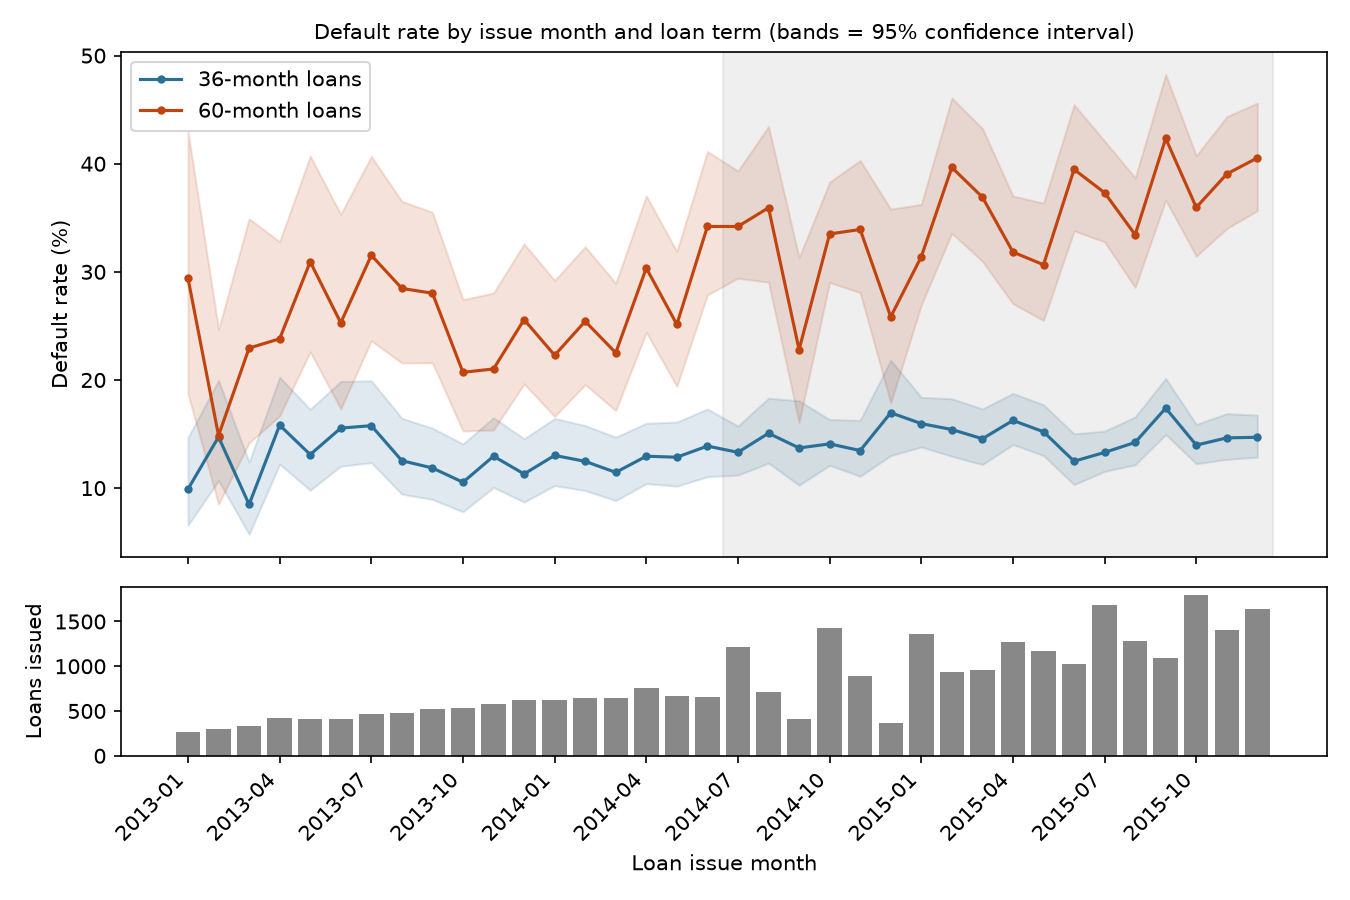

default_rate_by_term_and_half_year.png


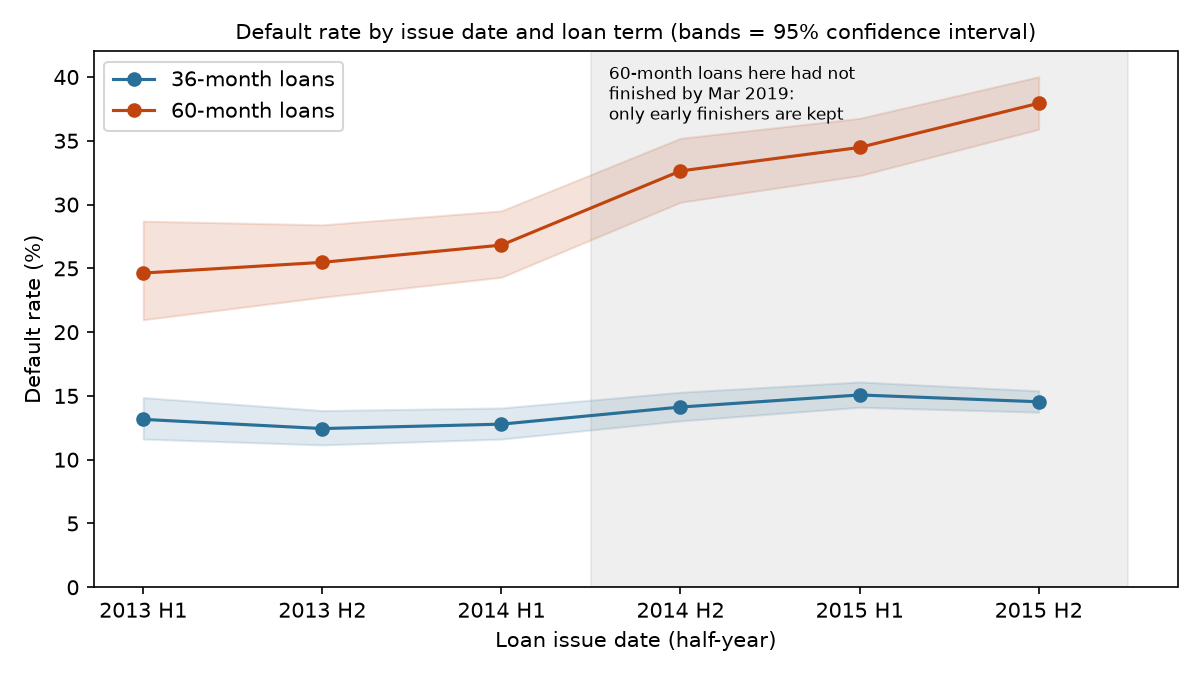

In [13]:
for p in sorted(Path("reports/a1_target_analysis/figures").glob("*.png")):
    print(p.name)
    display(Image(str(p)))

## The in-progress bias, in one picture

Whoever built the file kept only loans whose story had ended by March 2019: paid in full or defaulted. Loans still being repaid were removed.

- A **36-month** loan issued in 2015 had ended by 2019, so every such loan is in the file. Its default rate (about 13-15%) is trustworthy.
- A **60-month** loan issued from mid-2014 on had mostly or entirely *not* ended (see the `share_matured` column above: 48% for early 2014, 0% after). It is in the file only if it was paid off early or defaulted early. The borrowers still quietly paying were removed, so the remaining loans contain too many defaults. That is why the 60-month rate climbs from about 25% to about 38%.

We cannot undo this because we never see how the removed loans ended. What we do instead: **keep these loans but flag them, report every result separately by term, treat the 60-month calibration with caution, and never read the 2013-2015 rise as a change in the market.** Ranking metrics like AUC are less affected than predicted probabilities.

*Say it back (one or two sentences each, in your own words):*
1. Why do we drop only duplicates and repair the rest?
2. Why does `loan_servicing` exist if no model ever uses it?
3. Why is the 60-month default rate of 2015 loans too high to trust?